<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES1_MONTY_HALL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MONTY HALL PROBLEM**



*   Simulate three doors, one car, and two goats.

*   Simulate three players: the switcher, the conservative, and the
newcomer.

*   Record who wins.

*   Repeat it many times.

Which player do you want to be?

You could plot the winning probabilities as a function of the number of games. That tells you about the variance of your estimator.


In [45]:
import numpy as np
import random as rd
import matplotlib.pyplot as plt




*   3 DOORS SIMULATION





In [46]:
def monty_hall(N):
  N_cons=0
  N_switc=0
  N_nw=0
  for i in range(N):
    doors = np.zeros(3)
    carpos = rd.randint(0,2) #car position
    doors[carpos]=1
    scelta = rd.randint(0,2)
    apre = [0,1,2] #array posizioni apre posizione giudice

    if scelta != carpos :
        apre.remove(carpos)
        apre.remove(scelta)
        posDoorApre= apre[0] #pos porta da aprire se scelta=car
        N_switc=N_switc +1 #lo switcher vince quando il conservatore perde

    if scelta == carpos :
        apre.remove(scelta)
        posDoorApre = apre[rd.randint(0,1)] #pos porta da aprire se scelta!=car
        N_cons=N_cons+1 #p vincita conservatore non cambia se apre o no la porta
    doors = np.delete(doors, posDoorApre) # array porte post apertura giudice

    if doors[rd.randint(0,1)]==1:
        N_nw=N_nw + 1

  return(N_cons/N,N_switc/N,N_nw/N)

0.332
0.668
0.4937


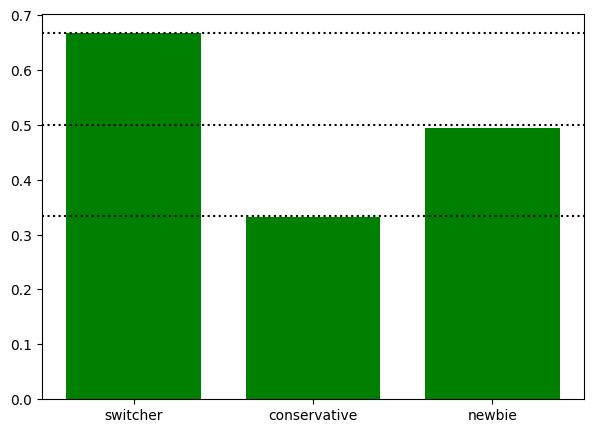

In [47]:
N = 10000

N_cons,N_switc,N_nw= monty_hall(N)

#plotting
categories=['switcher','conservative','newbie']
values=[N_switc,N_cons,N_nw]

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(categories, values, color='green', width=0.75)
for y in [1/3,1/2,2/3]:
    plt.axhline(y, ls='dotted',c='black')

print(N_cons)
print(N_switc)
print(N_nw)




*   ESTIMATOR CONVERGENCE




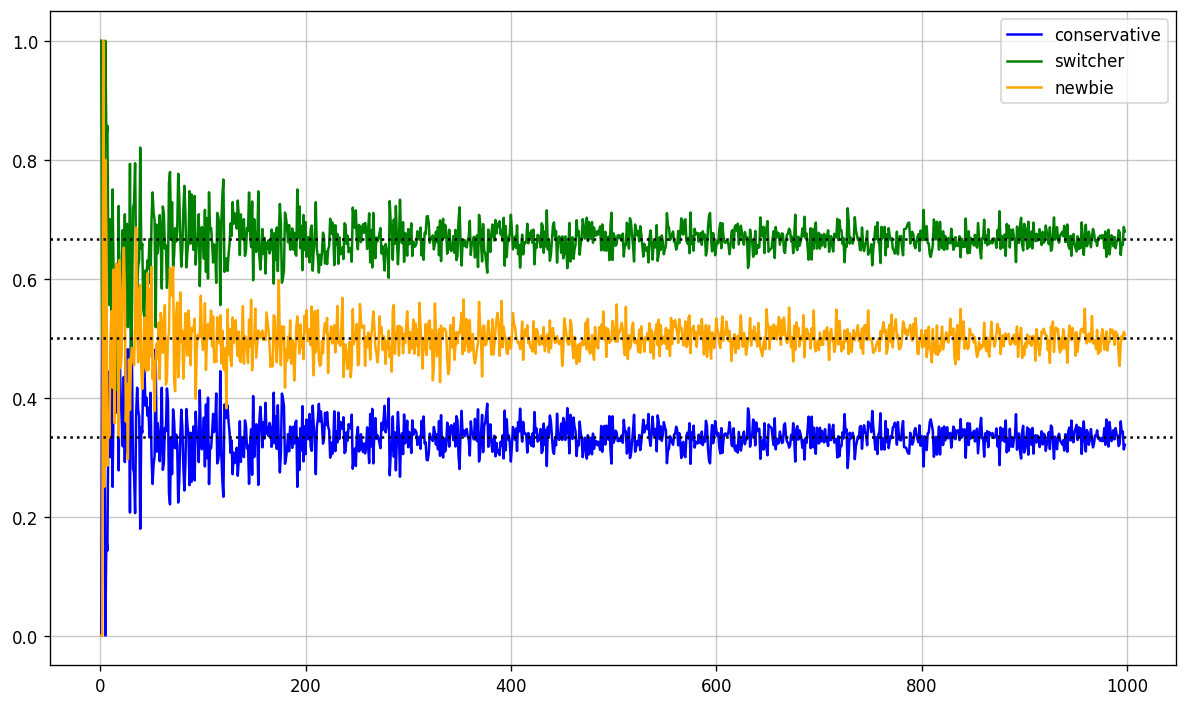

In [48]:
N = 1000
N_cons_array=[]
N_switc_array=[]
N_nw_array=[]
n=np.arange(1,N-1)

for j in (n):
  #iterating n times with variable n

  N_cons,N_switc,N_nw= monty_hall(j)

  N_cons_array.append(N_cons)
  N_switc_array.append(N_switc)
  N_nw_array.append(N_nw)

#Plot
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
ax.plot(n, N_cons_array, label='conservative', color='blue',  linestyle='-')
ax.plot(n, N_switc_array, label='switcher', color='green',  linestyle='-')
ax.plot(n, N_nw_array, label='newbie', color='orange',  linestyle='-')
for y in [1/3,1/2,2/3]:
      plt.axhline(y, ls='dotted',c='black')
ax.grid(True, alpha=0.7)
ax.legend(loc='best', frameon=True, shadow=False, fancybox=True)
plt.tight_layout()
plt.show()


*   DISTRIBUTION OF THE ESTIMATOR

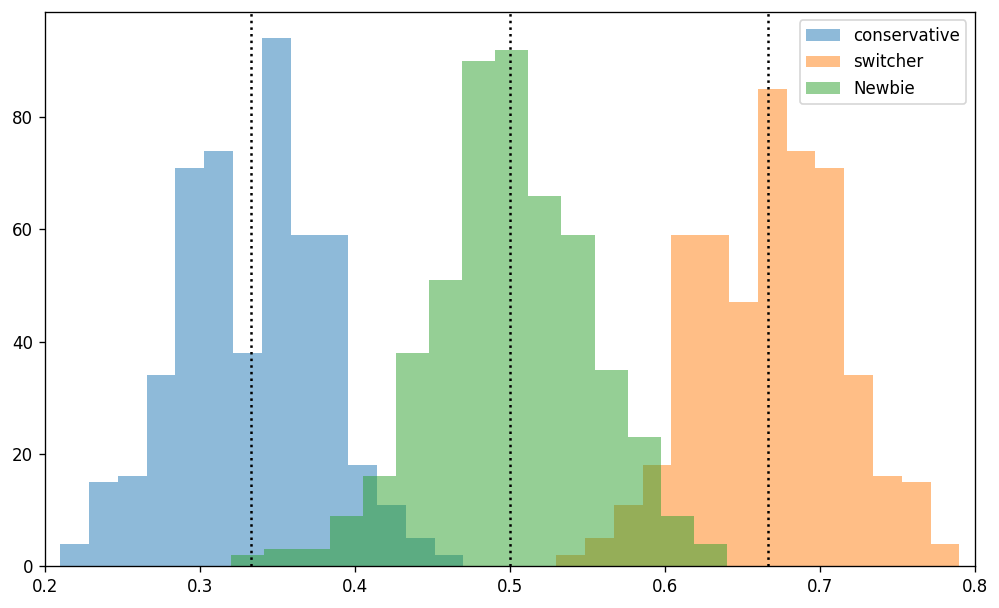

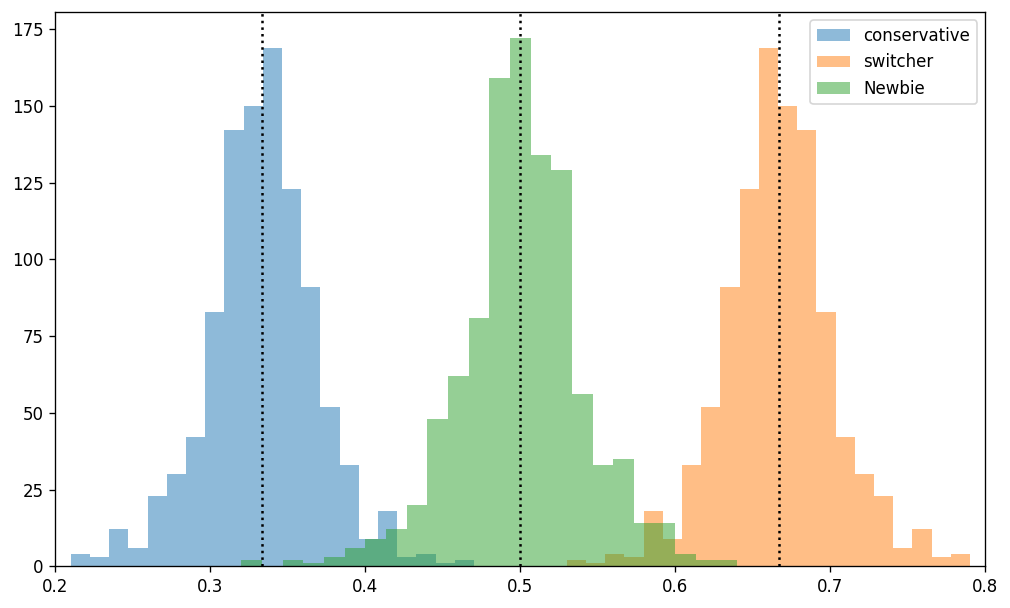

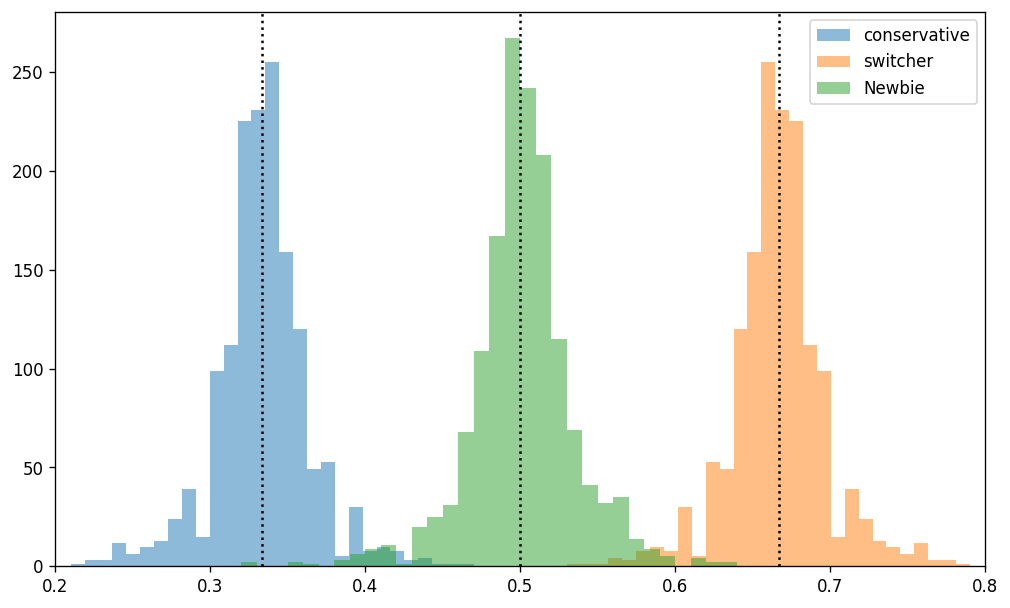

In [49]:
N_cons_array1=[]
N_switc_array1=[]
N_nw_array1=[]
width=[100,500,1000]

for width in width:
#iterating 500 times with fixed N

  for j in range (500):
    N_cons,N_switc,N_nw= monty_hall(width)
    N_cons_array1.append(N_cons)
    N_switc_array1.append(N_switc)
    N_nw_array1.append(N_nw)

  #plotting

  fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
  ax.set_xlim(0.2, 0.8)
  plt.hist(N_cons_array1, bins='scott', alpha=0.5, label='conservative')
  plt.hist(N_switc_array1, bins='scott', alpha=0.5, label='switcher')
  plt.hist(N_nw_array1, bins='scott', alpha=0.5, label='Newbie')

  for x in [1/3,1/2,2/3]:
      plt.axvline(x, ls='dotted',c='black')

  plt.legend()
  plt.show()


* THE DISTRIBUTION IS A GAUSSIAN WITH MEAN = TRUE_VALUE AND VARIANCE PROPORTIONAL TO 1/N

